# Cross-Lingual Alignment & Causal Patching Analysis (XCOPA, Belebele, XStoryCloze)
This notebook extends your **Llama3.2-1B** workflow across **XCOPA**, **Belebele**, and **XStoryCloze** to cover both correlational and causal analyses:
1. **Overall Cross-Lingual Alignment Table** (Paper Table 3 style: DALI, DALI-Strong, MEXA at $\lambda_{\max}$).
2. **TS vs. TF Separation** & **$\Delta_{\text{TS-TF}}$ with one-sided z-test $p$-values** across all tasks, languages, and metrics.
3. **Paper-Style $\Delta_{\text{TS-TF}}$ Summary Tables** (with significance stars `*`, `**`, `***` + LaTeX export).
4. **Grouped Bar Charts** comparing $\Delta_{\text{TS-TF}}$ across languages, metrics, and tasks.
5. **Layer-Wise TS vs. TF Alignment Curves** (Layers 0–16) to pinpoint where alignment separates TS from TF.
6. **TF Index Export** for activation patching + **Activation Patching Recovery Plot** (Paper Figure 2 style: % of TF flipped to TS per layer).


## 1. Imports & Multi-Task Configuration


In [10]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest

# --- Global Configuration ---
LLM_NAME = "Llama3.2-1B"
NUM_LAYERS = 17  # Layers 0..16 for Llama3.2-1B
METRICS = ["dali", "dali_strong", "mexa"]

ACCURACY_BASE_DIR = Path("../results/accuracy")
ALIGNMENT_BASE_DIR = Path("../alignment_results")
PATCHING_BASE_DIR = Path("../results/patching")

# Task-specific configurations:
# - num_samples: number of samples present in your alignment JSONs
# - lang_map: {alignment_filename_keyword: accuracy_file_lang_code}
# - eng_pattern / lang_pattern: filename templates inside ../results/accuracy/{LLM_NAME}/{task}/
TASK_CONFIGS = {
    "xcopa": {
        "num_samples": 167,
        "lang_map": {
            "italian": "it",
            "thai": "th",
        },
        "eng_pattern": "xcopa_eval_{llm}_translation-{lang}_AB.jsonl",
        "lang_pattern": "xcopa_eval_{llm}_{lang}_AB.jsonl",
    },
    "belebele": {
        "num_samples": 300,
        "lang_map": {
            "french": "fra_Latn",
            "spanish": "spa_Latn",
            "italian": "ita_Latn",
            "hindi": "hin_Deva",
            "thai": "tha_Thai",
        },
        "eng_pattern": "belebele_eval_{llm}_eng_Latn_ABCD.jsonl",
        "lang_pattern": "belebele_eval_{llm}_{lang}_ABCD.jsonl",
    },
    "xstorycloze": {
        "num_samples": 504,
        "lang_map": {
            "spanish": "es",
            "hindi": "hi",
            "chinese": "zh",
            "arabic": "ar",
        },
        "eng_pattern": "xstorycloze_eval_{llm}_en_AB.jsonl",
        "lang_pattern": "xstorycloze_eval_{llm}_{lang}_AB.jsonl",
    },
}

# Choose which tasks to run
ACTIVE_TASKS = ["xcopa", "belebele", "xstorycloze"]


## 2. Data Loading & Helper Functions


In [11]:
def load_accuracy_df(filepath):
    if not filepath.exists():
        return None
    return pd.read_json(filepath, lines=True)

def separate_ts_tf(task, eval_lang, llm_name=LLM_NAME):
    cfg = TASK_CONFIGS[task]
    folder = ACCURACY_BASE_DIR / llm_name / task
    eng_path = folder / cfg["eng_pattern"].format(llm=llm_name, lang=eval_lang)
    lang_path = folder / cfg["lang_pattern"].format(llm=llm_name, lang=eval_lang)

    eng_df = load_accuracy_df(eng_path)
    lang_df = load_accuracy_df(lang_path)
    if eng_df is None or lang_df is None:
        return None, None

    num_samples = cfg["num_samples"]
    eng_df = eng_df[eng_df["idx"] < num_samples]
    lang_df = lang_df[lang_df["idx"] < num_samples]

    merged = eng_df[["idx", "acc"]].merge(
        lang_df[["idx", "acc"]],
        on="idx",
        suffixes=("_eng", "_lang")
    )

    ts_df = merged[(merged["acc_eng"] == 1.0) & (merged["acc_lang"] == 1.0)].reset_index(drop=True)
    tf_df = merged[(merged["acc_eng"] == 1.0) & (merged["acc_lang"] == 0.0)].reset_index(drop=True)
    return ts_df, tf_df

def find_alignment_file(task, metric, align_lang, llm_name=LLM_NAME):
    metric_dir = ALIGNMENT_BASE_DIR / llm_name / task / metric
    if not metric_dir.exists():
        return None
    files = list(metric_dir.glob(f"*{align_lang}*.json"))
    return files[0] if files else None

def load_alignment_df(align_json_path, num_layers=NUM_LAYERS):
    align_df = pd.read_json(align_json_path)
    if align_df.shape[0] != num_layers and align_df.shape[1] == num_layers:
        align_df = align_df.T
    return align_df

def sig_stars(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


## 3. Compute Overall Alignment (Table 3 Style) & $\Delta_{\text{TS-TF}}$ Across All Tasks


In [12]:
def compute_delta_at_layer(align_df, ts_df, tf_df, layer_idx):
    offset = 1 if 0 not in align_df.columns else 0
    ts_cols = [c for c in (ts_df["idx"] + offset) if c in align_df.columns]
    tf_cols = [c for c in (tf_df["idx"] + offset) if c in align_df.columns]

    ts_align = align_df.loc[layer_idx, ts_cols]
    tf_align = align_df.loc[layer_idx, tf_cols]

    delta = (ts_align.mean() - tf_align.mean()) * 100
    if len(ts_align) > 0 and len(tf_align) > 0:
        _, p_val = proportions_ztest(
            [ts_align.sum(), tf_align.sum()],
            [len(ts_align), len(tf_align)],
            alternative="larger"
        )
    else:
        p_val = np.nan

    return {
        "n_TS": len(ts_align),
        "n_TF": len(tf_align),
        "overall_align_%": round(align_df.loc[layer_idx].mean() * 100, 2),
        "TS_align_%": round(ts_align.mean() * 100, 2),
        "TF_align_%": round(tf_align.mean() * 100, 2),
        "Delta_TS_TF_%": round(delta, 2),
        "p_value": round(float(p_val), 4) if pd.notna(p_val) else np.nan,
    }

ts_tf_splits = {}
all_results = []

for task in ACTIVE_TASKS:
    ts_tf_splits[task] = {}
    for align_lang, eval_lang in TASK_CONFIGS[task]["lang_map"].items():
        ts_df, tf_df = separate_ts_tf(task, eval_lang)
        if ts_df is None:
            print(f"[Skipping accuracy] {task} - {align_lang} ({eval_lang}) files not found.")
            continue

        ts_tf_splits[task][align_lang] = (ts_df, tf_df)
        print(f"[{task:11s}] {align_lang:8s} ({eval_lang:8s}): n_TS={len(ts_df):3d}, n_TF={len(tf_df):3d}")

        for metric in METRICS:
            json_path = find_alignment_file(task, metric, align_lang)
            if json_path is None:
                continue

            align_df = load_alignment_df(json_path)
            lambda_max = int(align_df.mean(axis=1).idxmax())
            stats = compute_delta_at_layer(align_df, ts_df, tf_df, lambda_max)

            all_results.append({
                "task": task,
                "language": align_lang,
                "metric": metric,
                "lambda_max": lambda_max,
                **stats
            })

results_df = pd.DataFrame(all_results)
display(results_df)


[xcopa      ] italian  (it      ): n_TS= 51, n_TF= 44
[xcopa      ] thai     (th      ): n_TS= 55, n_TF= 17
[belebele   ] french   (fra_Latn): n_TS= 78, n_TF=  1
[belebele   ] spanish  (spa_Latn): n_TS= 79, n_TF=  0
[belebele   ] italian  (ita_Latn): n_TS= 79, n_TF=  0
[belebele   ] hindi    (hin_Deva): n_TS= 79, n_TF=  0
[Skipping accuracy] belebele - thai (tha_Thai) files not found.
[xstorycloze] spanish  (es      ): n_TS=244, n_TF= 52
[xstorycloze] hindi    (hi      ): n_TS=233, n_TF= 63
[Skipping accuracy] xstorycloze - chinese (zh) files not found.
[Skipping accuracy] xstorycloze - arabic (ar) files not found.


,task,language,metric,lambda_max,n_TS,n_TF,overall_align_%,TS_align_%,TF_align_%,Delta_TS_TF_%,p_value
0,xcopa,italian,dali,5,51,44,73.65,82.35,59.09,23.26,0.0061
1,xcopa,italian,dali_strong,0,51,44,1.80,1.96,2.27,-0.31,0.5421
2,xcopa,italian,mexa,7,51,44,73.65,74.51,75.00,-0.49,0.5219
3,xcopa,thai,dali,5,55,17,38.32,38.18,23.53,14.65,0.1337
4,xcopa,thai,dali_strong,5,55,17,10.18,12.73,0.00,12.73,0.0608
5,xcopa,thai,mexa,5,55,17,44.91,36.36,41.18,-4.81,0.6399
6,xstorycloze,spanish,dali,8,244,52,97.22,95.90,98.08,-2.18,0.7742
7,xstorycloze,spanish,dali_strong,8,244,52,81.75,79.10,76.92,2.18,0.3639
8,xstorycloze,spanish,mexa,9,244,52,97.02,96.31,98.08,-1.77,0.7388
9,xstorycloze,hindi,dali,7,233,63,93.45,92.27,95.24,-2.96,0.7918


## 4. Paper-Style Summary Tables (Overall Alignment & $\Delta_{\text{TS-TF}}$)


In [13]:
if not results_df.empty:
    for task in ACTIVE_TASKS:
        sub = results_df[results_df["task"] == task].copy()
        if sub.empty:
            continue

        print(f"\n==================== {task.upper()} ====================")

        # 1. Overall Alignment Table (Table 3 style)
        align_table = sub.pivot(index="language", columns="metric", values="overall_align_%")
        print(f"\n[{task.upper()}] Overall Alignment (%) at lambda_max (Table 3 Style):")
        display(align_table)

        # 2. Delta_TS_TF Table with significance stars
        sub["formatted_delta"] = sub.apply(
            lambda r: f"{r['Delta_TS_TF_%']:+.2f}{sig_stars(r['p_value'])} (L{r['lambda_max']})",
            axis=1
        )
        delta_table = sub.pivot(index="language", columns="metric", values="formatted_delta")
        print(f"\n[{task.upper()}] Delta_TS-TF (%) with Significance Markers:")
        display(delta_table)




==================== XCOPA ====================

[XCOPA] Overall Alignment (%) at lambda_max (Table 3 Style):


metric,dali,dali_strong,mexa
language,,,
italian,73.65,1.80,73.65
thai,38.32,10.18,44.91



[XCOPA] Delta_TS-TF (%) with Significance Markers:


metric,dali,dali_strong,mexa
language,,,
italian,+23.26** (L5),-0.31 (L0),-0.49 (L7)
thai,+14.65 (L5),+12.73 (L5),-4.81 (L5)



==================== XSTORYCLOZE ====================

[XSTORYCLOZE] Overall Alignment (%) at lambda_max (Table 3 Style):


metric,dali,dali_strong,mexa
language,,,
hindi,93.45,38.89,83.93
spanish,97.22,81.75,97.02



[XSTORYCLOZE] Delta_TS-TF (%) with Significance Markers:


metric,dali,dali_strong,mexa
language,,,
hindi,-2.96 (L7),+4.99 (L8),+6.90 (L8)
spanish,-2.18 (L8),+2.18 (L8),-1.77 (L9)


## 5. Grouped Bar Charts: $\Delta_{\text{TS-TF}}$ Across Languages & Metrics


<>:35: SyntaxWarning: invalid escape sequence '\D'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\D'
<>:35: SyntaxWarning: invalid escape sequence '\l'
<>:35: SyntaxWarning: invalid escape sequence '\m'
C:\Users\cream\AppData\Local\Temp\ipykernel_33548\2608989511.py:35: SyntaxWarning: invalid escape sequence '\D'
  ax.set_title(f"{LLM_NAME} — {task.upper()}: $\Delta_{{\text{{TS-TF}}}}$ at $\lambda_{{\max}}$")
C:\Users\cream\AppData\Local\Temp\ipykernel_33548\2608989511.py:35: SyntaxWarning: invalid escape sequence '\l'
  ax.set_title(f"{LLM_NAME} — {task.upper()}: $\Delta_{{\text{{TS-TF}}}}$ at $\lambda_{{\max}}$")
C:\Users\cream\AppData\Local\Temp\ipykernel_33548\2608989511.py:35: SyntaxWarning: invalid escape sequence '\m'
  ax.set_title(f"{LLM_NAME} — {task.upper()}: $\Delta_{{\text{{TS-TF}}}}$ at $\lambda_{{\max}}$")


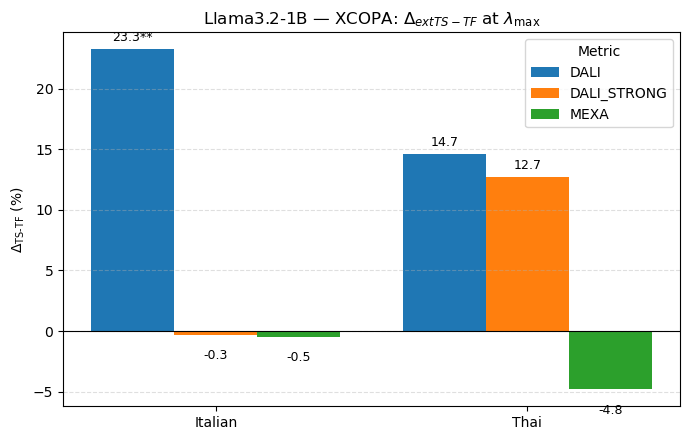

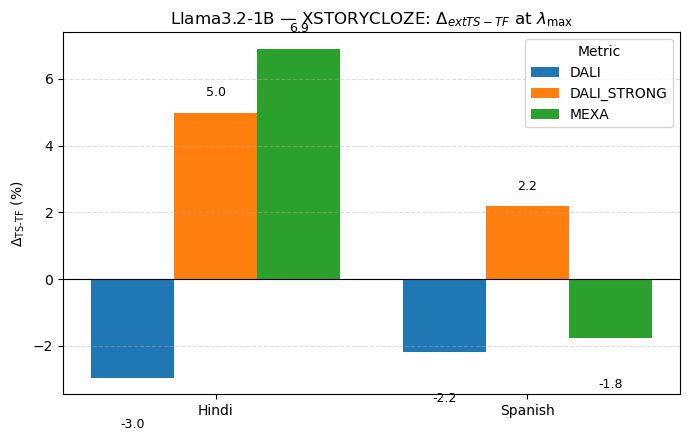

In [14]:
if not results_df.empty:
    for task in ACTIVE_TASKS:
        sub = results_df[results_df["task"] == task]
        if sub.empty:
            continue

        pivot_delta = sub.pivot(index="language", columns="metric", values="Delta_TS_TF_%")
        pivot_pval = sub.pivot(index="language", columns="metric", values="p_value")

        languages = pivot_delta.index.tolist()
        avail_metrics = pivot_delta.columns.tolist()
        x = np.arange(len(languages))
        width = 0.8 / max(len(avail_metrics), 1)

        fig, ax = plt.subplots(figsize=(max(7, 1.8 * len(languages)), 4.5))
        for i, metric in enumerate(avail_metrics):
            vals = pivot_delta[metric].values
            pvals = pivot_pval[metric].values
            bars = ax.bar(x + i * width - (len(avail_metrics) - 1) * width / 2, vals, width, label=metric.upper())

            for bar, val, pv in zip(bars, vals, pvals):
                if pd.notna(val):
                    offset_y = 0.4 if val >= 0 else -1.2
                    ax.text(
                        bar.get_x() + bar.get_width() / 2,
                        val + offset_y,
                        f"{val:.1f}{sig_stars(pv)}",
                        ha="center", va="bottom" if val >= 0 else "top", fontsize=9
                    )

        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels([l.capitalize() for l in languages])
        ax.set_ylabel(r"$\Delta_{\text{TS-TF}}$ (%)")
        ax.set_title(f"{LLM_NAME} — {task.upper()}: $\Delta_{{\text{{TS-TF}}}}$ at $\lambda_{{\max}}$")
        ax.legend(title="Metric")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        plt.tight_layout()
        plt.show()


## 6. Layer-Wise TS vs. TF Alignment Curves (Layers 0–16)


<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\l'
<>:32: SyntaxWarning: invalid escape sequence '\m'
C:\Users\cream\AppData\Local\Temp\ipykernel_33548\1023336335.py:32: SyntaxWarning: invalid escape sequence '\l'
  ax.axvline(lambda_max, color="gray", linestyle=":", label=f"$\lambda_{{\max}}$={lambda_max}")
C:\Users\cream\AppData\Local\Temp\ipykernel_33548\1023336335.py:32: SyntaxWarning: invalid escape sequence '\m'
  ax.axvline(lambda_max, color="gray", linestyle=":", label=f"$\lambda_{{\max}}$={lambda_max}")


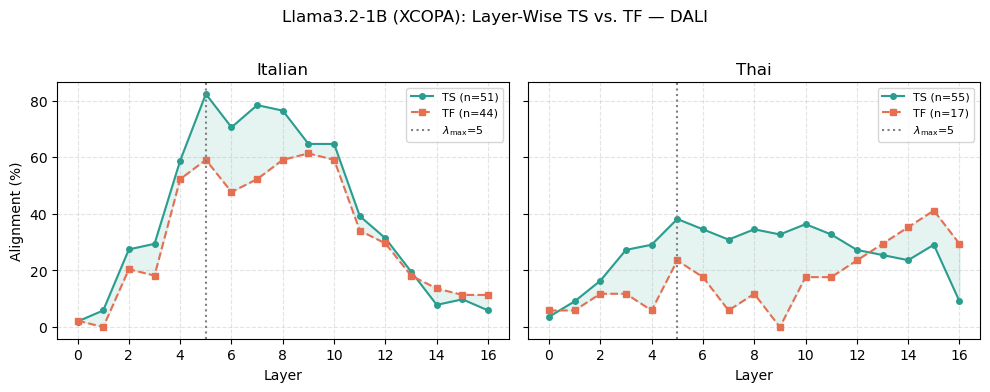

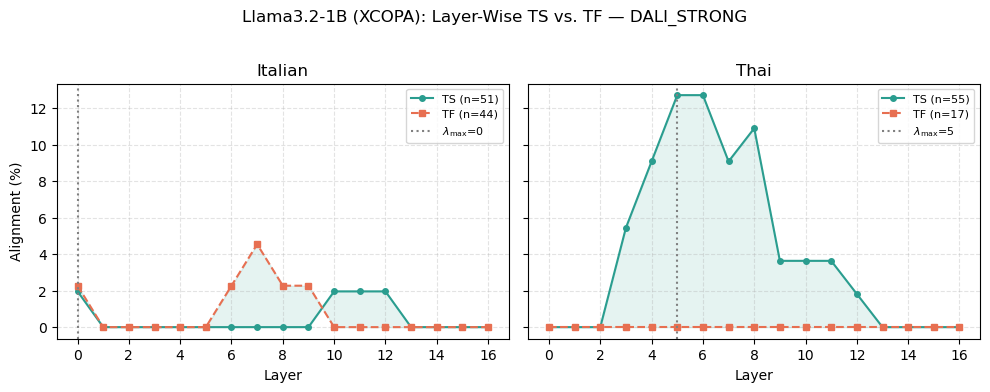

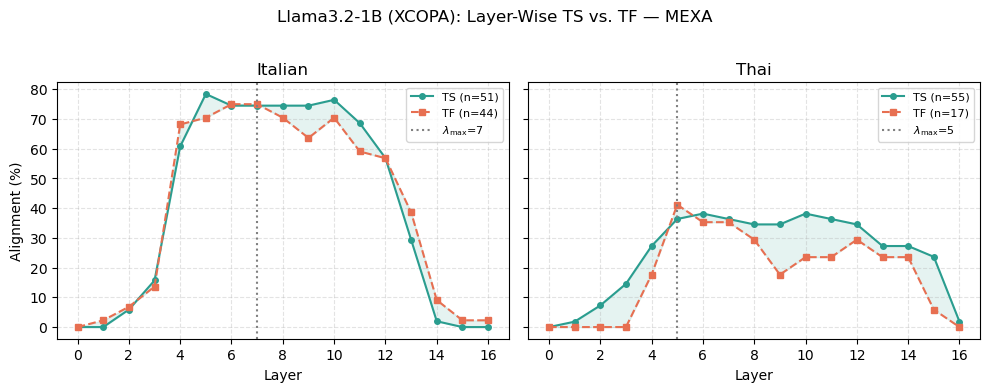

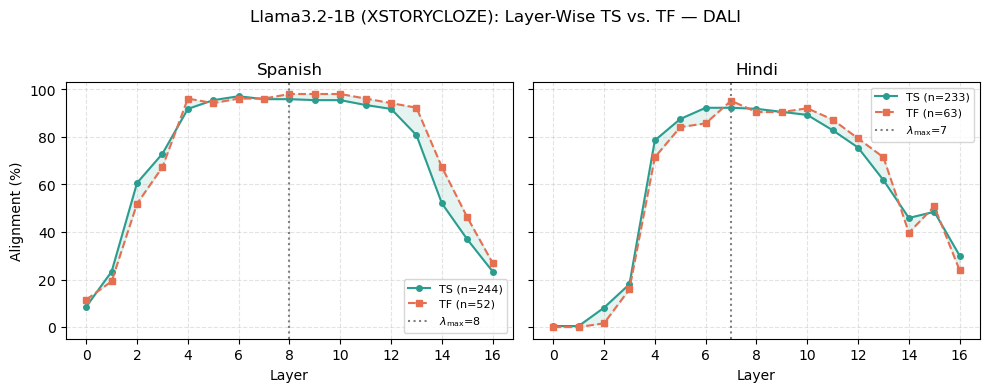

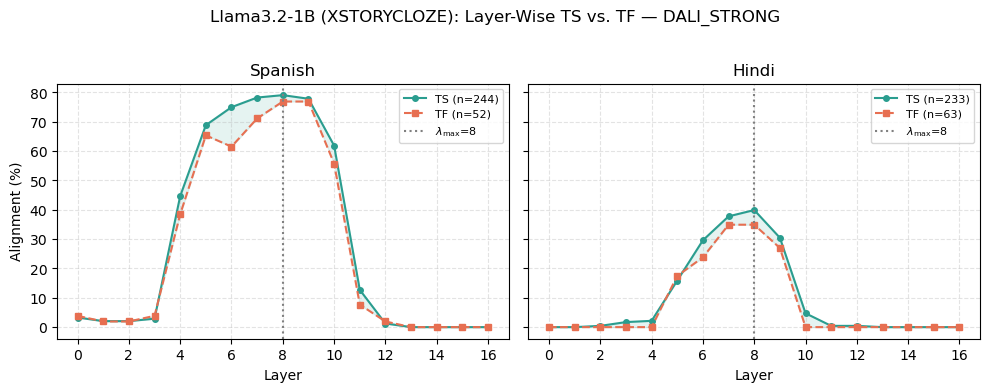

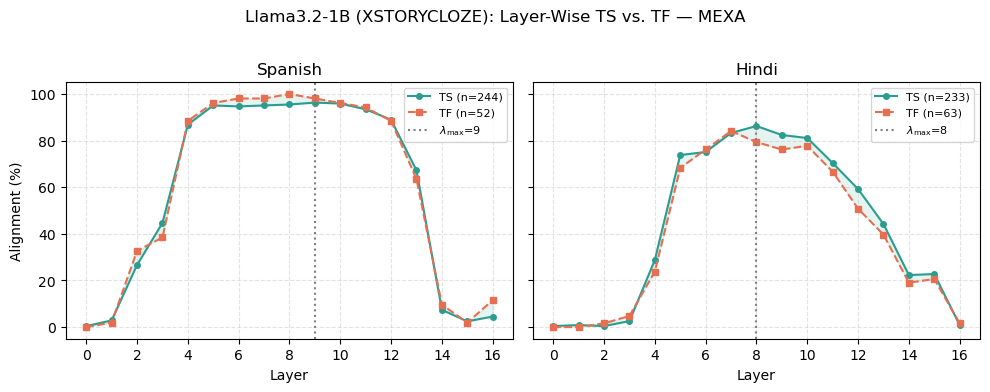

In [15]:
def compute_layerwise_curves(align_df, ts_df, tf_df):
    offset = 1 if 0 not in align_df.columns else 0
    ts_cols = [c for c in (ts_df["idx"] + offset) if c in align_df.columns]
    tf_cols = [c for c in (tf_df["idx"] + offset) if c in align_df.columns]
    return align_df[ts_cols].mean(axis=1) * 100, align_df[tf_cols].mean(axis=1) * 100

for task in ACTIVE_TASKS:
    if task not in ts_tf_splits or not ts_tf_splits[task]:
        continue

    for metric in METRICS:
        valid_langs = [
            l for l in ts_tf_splits[task].keys()
            if find_alignment_file(task, metric, l) is not None
        ]
        if not valid_langs:
            continue

        fig, axes = plt.subplots(1, len(valid_langs), figsize=(5 * len(valid_langs), 3.8), sharey=True)
        if len(valid_langs) == 1:
            axes = [axes]

        for ax, align_lang in zip(axes, valid_langs):
            align_df = load_alignment_df(find_alignment_file(task, metric, align_lang))
            ts_df, tf_df = ts_tf_splits[task][align_lang]
            ts_curve, tf_curve = compute_layerwise_curves(align_df, ts_df, tf_df)
            lambda_max = int(align_df.mean(axis=1).idxmax())

            layers = align_df.index
            ax.plot(layers, ts_curve, marker="o", markersize=4, label=f"TS (n={len(ts_df)})", color="#2a9d8f")
            ax.plot(layers, tf_curve, marker="s", markersize=4, linestyle="--", label=f"TF (n={len(tf_df)})", color="#e76f51")
            ax.axvline(lambda_max, color="gray", linestyle=":", label=f"$\lambda_{{\max}}$={lambda_max}")
            ax.fill_between(layers, tf_curve, ts_curve, alpha=0.12, color="#2a9d8f")

            ax.set_title(f"{align_lang.capitalize()}")
            ax.set_xlabel("Layer")
            ax.set_xticks(range(0, NUM_LAYERS, 2))
            ax.grid(True, linestyle="--", alpha=0.35)
            ax.legend(fontsize=8)

        axes[0].set_ylabel("Alignment (%)")
        fig.suptitle(f"{LLM_NAME} ({task.upper()}): Layer-Wise TS vs. TF — {metric.upper()}", y=1.02)
        plt.tight_layout()
        plt.show()


## 7. Causal Verification: Export TF Indices & Plot Activation Patching (Figure 2 Style)
1. **Export:** Saves `tf_indices` and `ts_indices` for each task/language into `../results/patching/{LLM_NAME}/{task}/`.
2. **Visualize:** Once your patching runs finish (saving per-layer recovery JSON/CSV files in `../results/patching/{LLM_NAME}/{task}/`), the plotting cell below renders the **Figure 2** style layer-wise recovery curve (% of TF samples flipped to correct).


In [16]:
# 7A. Export TF indices for patching
for task in ACTIVE_TASKS:
    if task not in ts_tf_splits or not ts_tf_splits[task]:
        continue

    out_dir = PATCHING_BASE_DIR / LLM_NAME / task
    out_dir.mkdir(parents=True, exist_ok=True)

    for align_lang, (ts_df, tf_df) in ts_tf_splits[task].items():
        out_file = out_dir / f"{align_lang}_tf_indices.json"
        payload = {
            "llm": LLM_NAME,
            "task": task,
            "language": align_lang,
            "num_samples_evaluated": TASK_CONFIGS[task]["num_samples"],
            "n_TS": len(ts_df),
            "n_TF": len(tf_df),
            "tf_indices": tf_df["idx"].astype(int).tolist(),
            "ts_indices": ts_df["idx"].astype(int).tolist(),
        }
        with open(out_file, "w") as f:
            json.dump(payload, f, indent=2)
        print(f"Saved {len(tf_df):3d} TF indices -> {out_file}")


Saved  44 TF indices -> ..\results\patching\Llama3.2-1B\xcopa\italian_tf_indices.json
Saved  17 TF indices -> ..\results\patching\Llama3.2-1B\xcopa\thai_tf_indices.json
Saved   1 TF indices -> ..\results\patching\Llama3.2-1B\belebele\french_tf_indices.json
Saved   0 TF indices -> ..\results\patching\Llama3.2-1B\belebele\spanish_tf_indices.json
Saved   0 TF indices -> ..\results\patching\Llama3.2-1B\belebele\italian_tf_indices.json
Saved   0 TF indices -> ..\results\patching\Llama3.2-1B\belebele\hindi_tf_indices.json
Saved  52 TF indices -> ..\results\patching\Llama3.2-1B\xstorycloze\spanish_tf_indices.json
Saved  63 TF indices -> ..\results\patching\Llama3.2-1B\xstorycloze\hindi_tf_indices.json


In [17]:
# 7B. Plot Activation Patching Recovery Curves (Paper Figure 2 Style)
# Expects per-language JSON files like:
#   ../results/patching/Llama3.2-1B/{task}/*{lang}*patching*.json
# Format supported: {"0": 0.12, "1": 0.18, ...} (layer -> fraction of TF flipped to TS)
# or a list of length NUM_LAYERS.

for task in ACTIVE_TASKS:
    patch_dir = PATCHING_BASE_DIR / LLM_NAME / task
    if not patch_dir.exists():
        continue

    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    plotted = False

    for align_lang in TASK_CONFIGS[task]["lang_map"].keys():
        patch_files = list(patch_dir.glob(f"*{align_lang}*patch*.json"))
        if not patch_files:
            continue

        with open(patch_files[0], "r") as f:
            data = json.load(f)

        if isinstance(data, dict):
            layers = sorted([int(k) for k in data.keys()])
            vals = [data[str(l)] * 100 if data[str(l)] <= 1.0 else data[str(l)] for l in layers]
        elif isinstance(data, list):
            layers = list(range(len(data)))
            vals = [v * 100 if v <= 1.0 else v for v in data]
        else:
            continue

        ax.plot(layers, vals, marker="o", markersize=4, label=align_lang.capitalize())
        plotted = True

    if plotted:
        ax.set_title(f"{LLM_NAME} — {task.upper()}: Activation Patching Recovery (TF → TS)")
        ax.set_xlabel("Patched Layer")
        ax.set_ylabel("% of TF Flipped to Correct")
        ax.set_xticks(range(0, NUM_LAYERS, 2))
        ax.set_ylim(0, 100)
        ax.grid(True, linestyle="--", alpha=0.4)
        ax.legend(title="Language")
        plt.tight_layout()
        plt.show()
    else:
        plt.close(fig)
        print(f"[Info] No patching result JSONs found yet in {patch_dir}")


[Info] No patching result JSONs found yet in ..\results\patching\Llama3.2-1B\xcopa
[Info] No patching result JSONs found yet in ..\results\patching\Llama3.2-1B\belebele
[Info] No patching result JSONs found yet in ..\results\patching\Llama3.2-1B\xstorycloze
